# Tier-1 OCR: invoice image vs extracted totals

Prereqs: `python scripts/download_data.py` and `python -m src.db.db`. RapidOCR takes ~13s/image on CPU.

In [1]:
import base64
import html
import io
import os
import sqlite3
from pathlib import Path

from IPython.display import HTML, display
from PIL import Image
from pydantic import ValidationError

os.chdir(Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd())

from src.automate.ocr import ocr_text, parse_totals
from src.constants import CENT
from src.db.db import get_paths

In [2]:
N, OFFSET = 5, 0  # which invoices to show

rows = (
    sqlite3.connect(get_paths()[0])
    .execute(
        "SELECT image_path, invoice_no, seller, total_net, total_vat, total_gross"
        " FROM invoices ORDER BY id LIMIT ? OFFSET ?",
        (N, OFFSET),
    )
    .fetchall()
)

,ground truth,OCR
net,7.50,7.50
VAT,0.75,0.75
gross,8.25,8.25

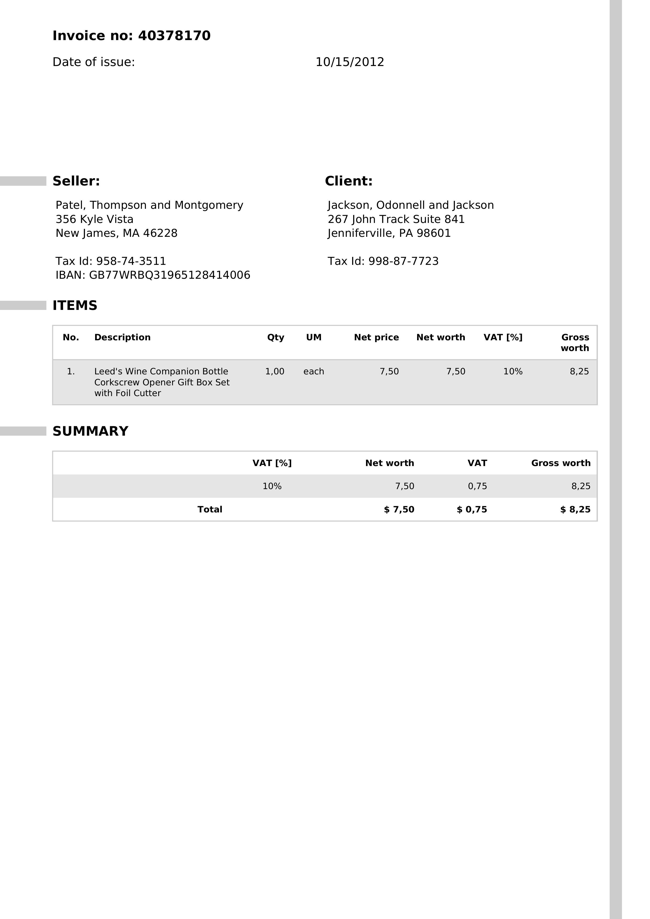

,ground truth,OCR
net,192.81,192.81
VAT,19.28,19.28
gross,212.09,212.09

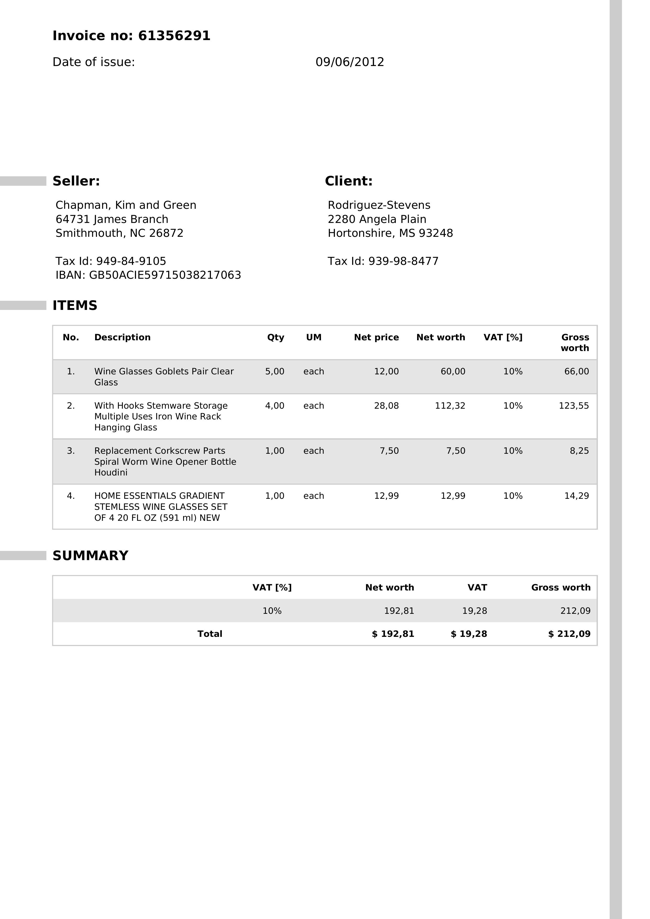

,ground truth,OCR
net,87.94,87.94
VAT,8.79,8.79
gross,96.73,96.73

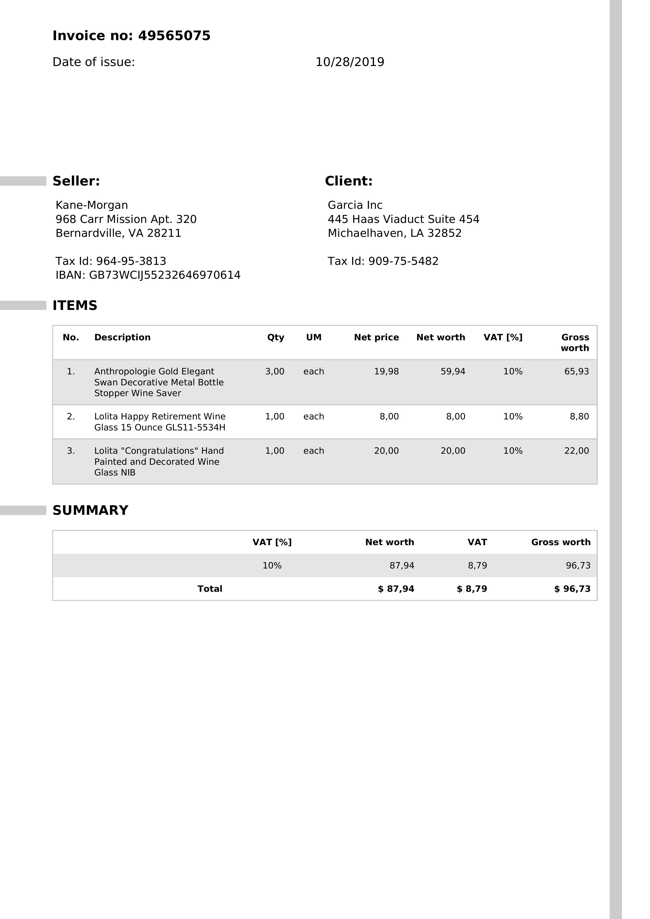

,ground truth,OCR
net,958.27,958.27
VAT,95.83,95.83
gross,"1,054.10","1,054.10"

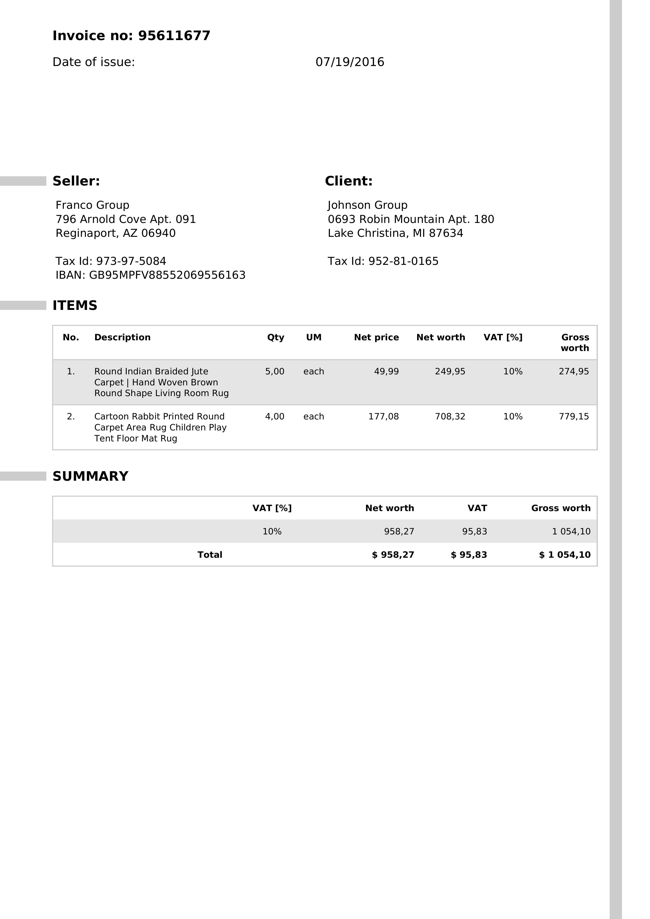

,ground truth,OCR
net,105.93,105.93
VAT,10.59,10.59
gross,116.52,116.52

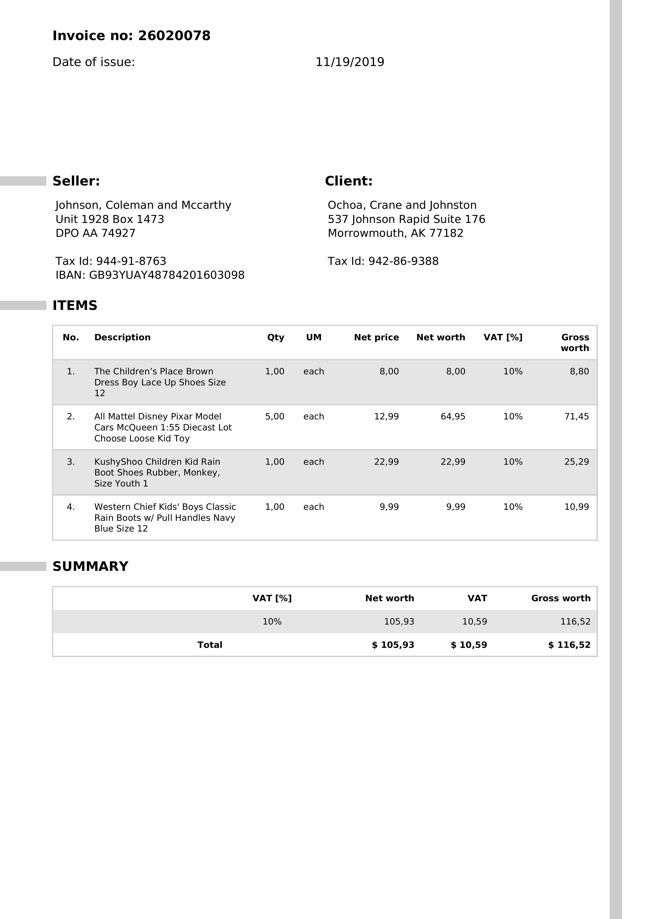

In [3]:
def img_tag(path, width=650):
    im = Image.open(path)
    im.thumbnail((width, width * 2))
    buf = io.BytesIO()
    im.save(buf, "PNG")
    return f'<img src="data:image/png;base64,{base64.b64encode(buf.getvalue()).decode()}">'


def compare(img, invoice_no, seller, *truth):
    text, conf = ocr_text(img)
    try:
        o = parse_totals(text, conf)
        got, status = [o.total_net, o.total_vat, o.total_gross], None
    except ValidationError as e:
        got, status = [None] * 3, f"gate failed: {e.errors()[0]['msg']}"
    except ValueError as e:
        got, status = [None] * 3, str(e)

    cells = ""
    for name, t, g in zip(["net", "VAT", "gross"], truth, got):
        ok = g is not None and abs(g - t) <= CENT
        color = "#d4edda" if ok else "#f8d7da"
        cells += f"<tr><td>{name}</td><td>{t:,.2f}</td><td style='background:{color}'>{'-' if g is None else f'{g:,.2f}'}</td></tr>"

    return f"""
    <div style='display:flex;gap:24px;align-items:flex-start;border-top:2px solid #888;padding:12px 0'>
      <div>{img_tag(img)}</div>
      <div style='min-width:380px'>
        <h3>{Path(img).name}</h3>
        <p>invoice #{html.escape(str(invoice_no))}<br>{html.escape(seller or '')}</p>
        <table><tr><th></th><th>ground truth</th><th>OCR</th></tr>{cells}</table>
        <p>confidence: {conf:.3f}{'<br><b>' + html.escape(status) + '</b>' if status else ''}</p>
        <details><summary>raw OCR text</summary><pre>{html.escape(text)}</pre></details>
      </div>
    </div>"""


for r in rows:
    display(HTML(compare(*r)))